In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [7]:
df = pd.read_excel("../data/data.xlsx")

In [9]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
df.shape

(541909, 8)

In [11]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [15]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [16]:
# Valeurs manquantes
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(5268)

In [18]:
df = df.drop_duplicates()

In [19]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,536641.000000,536641,536641.000000,401604.000000
mean,9.620029,2011-07-04 08:57:06.087421,4.632656,15281.160818
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 10:52:00,1.250000,13939.000000
50%,3.000000,2011-07-19 14:04:00,2.080000,15145.000000
75%,10.000000,2011-10-18 17:05:00,4.130000,16784.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,219.130156,NaN,97.233118,1714.006089


In [20]:
df["Quantity"].describe()

count    536641.000000
mean          9.620029
std         219.130156
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [21]:
df["UnitPrice"].describe()

count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

In [22]:
(df["Quantity"] < 0).sum()

np.int64(10587)

In [23]:
(df["UnitPrice"] <= 0).sum()

np.int64(2512)

In [24]:
df[df["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [25]:
df[df["UnitPrice"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [26]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

In [27]:
df.shape

(524878, 8)

In [28]:
df["CustomerID"].isnull().sum()

np.int64(132186)

In [29]:
df = df.dropna(subset=['CustomerID'])

In [30]:
df["CustomerID"].isnull().sum()

np.int64(0)

In [31]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

In [32]:
df[["Quantity", "UnitPrice", "TotalAmount"]].head()

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [33]:
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (df["InvoiceDate"].max() - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,1,77183.60
1,12347.0,1,7,4310.00
2,12348.0,74,4,1797.24
3,12349.0,18,1,1757.55
4,12350.0,309,1,334.40


In [34]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,91.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,0.000000,1.000000,3.750000
25%,17.000000,1.000000,306.482500
50%,50.000000,2.000000,668.570000
75%,141.000000,5.000000,1660.597500
max,373.000000,209.000000,280206.020000


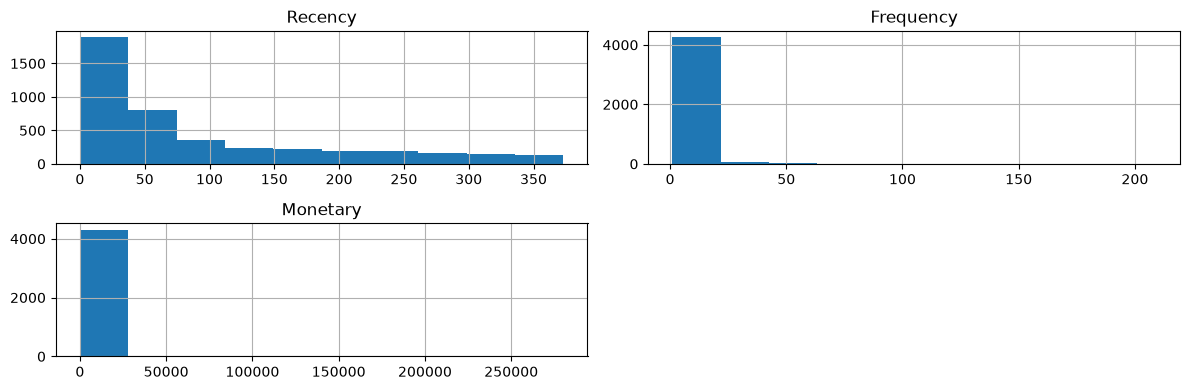

In [35]:
rfm[["Recency", "Frequency", "Monetary"]].hist(
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

In [36]:
rfm[["Recency", "Frequency", "Monetary"]].skew()

Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64

In [37]:
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

In [38]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

In [39]:
rfm_scaled[:5]

array([[ 1.40989446, -0.95521426,  3.7077163 ],
       [-2.14649825,  1.07442519,  1.41490344],
       [ 0.38397128,  0.38630445,  0.72002428],
       [-0.57467446, -0.95521426,  0.70228691],
       [ 1.37475812, -0.95521426, -0.61451388]])

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [41]:
inertias = []
silhouette_scores = []

for k in range(2, 10):

    model = KMeans(n_clusters=k)

    labels = model.fit_predict(rfm_scaled)

    inertias.append(model.inertia_)

    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

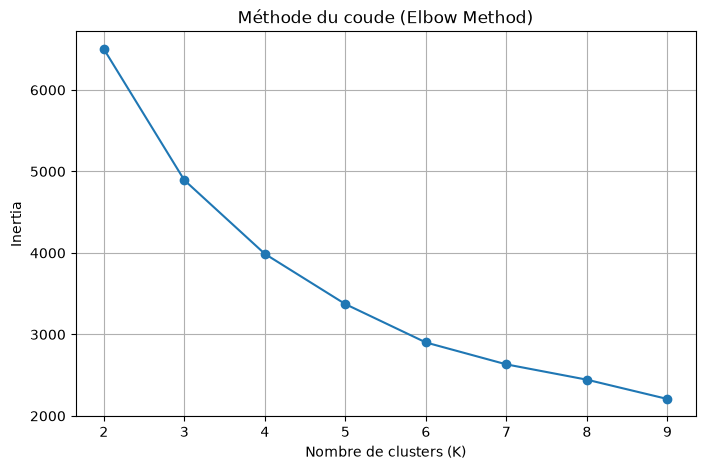

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 10),
    inertias,
    marker="o"
)

plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertia")
plt.title("Méthode du coude (Elbow Method)")
plt.xticks(range(2, 10))
plt.grid(True)

plt.show()

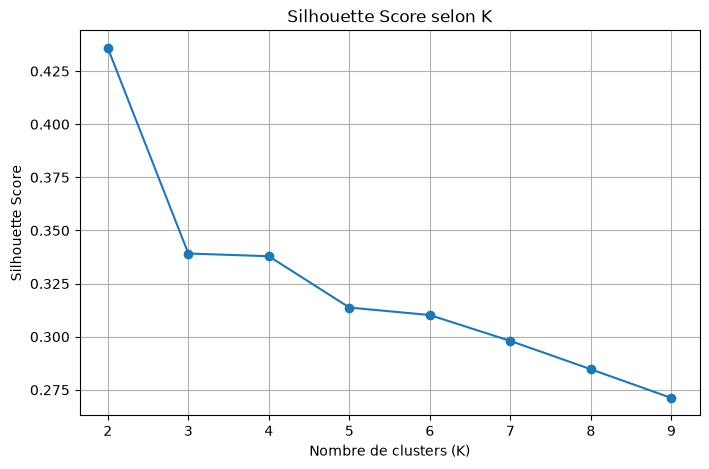

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 10),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score selon K")
plt.xticks(range(2, 10))
plt.grid(True)

plt.show()

In [44]:
for k, inertia, score in zip(
    range(2, 10),
    inertias,
    silhouette_scores
):
    print(
        f"K = {k} | "
        f"Inertia = {inertia:.2f} | "
        f"Silhouette = {score:.3f}"
    )

K = 2 | Inertia = 6502.63 | Silhouette = 0.436
K = 3 | Inertia = 4893.25 | Silhouette = 0.339
K = 4 | Inertia = 3988.39 | Silhouette = 0.338
K = 5 | Inertia = 3371.92 | Silhouette = 0.314
K = 6 | Inertia = 2901.12 | Silhouette = 0.310
K = 7 | Inertia = 2632.14 | Silhouette = 0.298
K = 8 | Inertia = 2444.30 | Silhouette = 0.285
K = 9 | Inertia = 2207.37 | Silhouette = 0.271


## Segmentation finale avec K-Means (K = 3)

Les methodes Elbow et Silhouette donnent une indication algorithmique sur le nombre de clusters. Pour respecter la contrainte metier du brief, on fixe ici le nombre final de segments a **K = 3**.

In [ ]:
features = ["Recence", "Frequence", "Montant"]

rfm_final = rfm.rename(
    columns={
        "Recency": "Recence",
        "Frequency": "Frequence",
        "Monetary": "Montant",
    }
).copy()

rfm_final.head()

In [ ]:
rfm_log_final = np.log1p(rfm_final[features])

scaler_final = StandardScaler()
rfm_scaled_final = scaler_final.fit_transform(rfm_log_final)

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm_final["Cluster"] = kmeans_final.fit_predict(rfm_scaled_final)

rfm_final.head()

## Profiling et interpretation metier des segments

In [ ]:
cluster_profile = rfm_final.groupby("Cluster").agg(
    Nb_clients=("CustomerID", "count"),
    Recence_moyenne=("Recence", "mean"),
    Frequence_moyenne=("Frequence", "mean"),
    Montant_moyen=("Montant", "mean"),
    Chiffre_affaires=("Montant", "sum"),
)

cluster_profile["Contribution_CA_%"] = (
    cluster_profile["Chiffre_affaires"]
    / cluster_profile["Chiffre_affaires"].sum()
    * 100
)

segment_score = (
    cluster_profile["Montant_moyen"].rank(ascending=True)
    + cluster_profile["Frequence_moyenne"].rank(ascending=True)
    + cluster_profile["Recence_moyenne"].rank(ascending=False)
)

clusters_ordonnes = segment_score.sort_values().index.tolist()
segment_map = {
    clusters_ordonnes[0]: "Clients occasionnels / inactifs",
    clusters_ordonnes[1]: "Clients intermediaires",
    clusters_ordonnes[2]: "Clients a forte valeur",
}

segment_order = [segment_map[cluster] for cluster in clusters_ordonnes]
rfm_final["Segment"] = rfm_final["Cluster"].map(segment_map)

profile_app = rfm_final.groupby("Cluster")[features].mean()
profile = cluster_profile.round(2)
profile["Segment"] = profile.index.map(segment_map)

profile.sort_values("Contribution_CA_%", ascending=False)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=rfm_final,
    x="Segment",
    order=segment_order,
    ax=axes[0]
)
axes[0].set_title("Nombre de clients par segment")
axes[0].set_xlabel("")
axes[0].set_ylabel("Nombre de clients")
axes[0].tick_params(axis="x", rotation=20)

profile_by_segment = rfm_final.groupby("Segment")[features].mean().loc[segment_order]
profile_norm = (profile_by_segment - profile_by_segment.min()) / (
    profile_by_segment.max() - profile_by_segment.min()
)

sns.heatmap(
    profile_norm,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    ax=axes[1]
)
axes[1].set_title("Profil RFM normalise des segments")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## Visualisation des segments avec PCA

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_result = pca.fit_transform(rfm_scaled_final)

pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)
pca_df["Cluster"] = rfm_final["Cluster"].values
pca_df["Segment"] = rfm_final["Segment"].values

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Segment",
    hue_order=segment_order,
    palette="Set2",
    alpha=0.75,
    s=35
)
plt.title("Visualisation PCA des segments clients")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)")
plt.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

pd.Series(
    pca.explained_variance_ratio_,
    index=["PC1", "PC2"],
    name="Variance expliquee"
)

## Classification supervisee avec Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

X = rfm_final[features]
y = rfm_final["Cluster"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

y_pred = rf_model.predict(X_test)

metrics_summary = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
        "Score": [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, average="weighted", zero_division=0),
            recall_score(y_test, y_pred, average="weighted", zero_division=0),
            f1_score(y_test, y_pred, average="weighted", zero_division=0),
        ],
    }
)

print("Validation croisee - scores:", cv_scores.round(4))
print("Validation croisee - moyenne:", round(cv_scores.mean(), 4))
print("Validation croisee - ecart-type:", round(cv_scores.std(), 4))

display(metrics_summary)

labels_sorted = sorted(y.unique())
target_names = [segment_map[label] for label in labels_sorted]

report = classification_report(
    y_test,
    y_pred,
    labels=labels_sorted,
    target_names=target_names,
    zero_division=0,
    output_dict=True
)

display(pd.DataFrame(report).T.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=labels_sorted,
    cmap="Blues"
)
plt.title("Matrice de confusion - Random Forest")
plt.show()

## Importance des variables

In [ ]:
importance_df = pd.DataFrame(
    {
        "Variable": features,
        "Importance": rf_model.feature_importances_,
    }
).sort_values("Importance", ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Variable",
    palette="viridis"
)
plt.title("Importance des variables dans le Random Forest")
plt.tight_layout()
plt.show()

importance_df

## Prediction d'un nouveau client

In [ ]:
nouveau_client = pd.DataFrame(
    {
        "Recence": [30],
        "Frequence": [5],
        "Montant": [500.0],
    }
)

cluster_predit = int(rf_model.predict(nouveau_client)[0])
segment_predit = segment_map[cluster_predit]

prediction_result = nouveau_client.copy()
prediction_result["Cluster_predit"] = cluster_predit
prediction_result["Segment_predit"] = segment_predit

prediction_result

## Sauvegarde et rechargement du modele

In [ ]:
from pathlib import Path
import joblib

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
model_dir = project_root / "models"
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "customer_segmentation_model.pkl"

model_bundle = {
    "rf_model": rf_model,
    "kmeans_model": kmeans_final,
    "scaler": scaler_final,
    "segment_names": segment_map,
    "profile": profile_app,
    "cluster_profile": cluster_profile,
    "features": features,
}

joblib.dump(model_bundle, model_path)

loaded_bundle = joblib.load(model_path)
loaded_cluster = int(loaded_bundle["rf_model"].predict(nouveau_client)[0])
loaded_segment = loaded_bundle["segment_names"][loaded_cluster]

print(f"Modele sauvegarde dans: {model_path}")
print(f"Prediction apres rechargement: cluster {loaded_cluster} - {loaded_segment}")